Dataset:
   Experience  Salary
0           1      30
1           2      35
2           3      45
3           4      60
4           5      80
5           6     110
6           7     150
7           8     200
8           9     260
9          10     330

Predicted Values:
[ 34.77272727  33.40909091  40.49242424  56.02272727  80.
 112.42424242 153.29545455 202.61363636 260.37878788 326.59090909]

Mean Squared Error: 9.678030303030305
R2 Score: 0.9989944903581267

Predicted Salary for 6 Years: 112.42424242424241


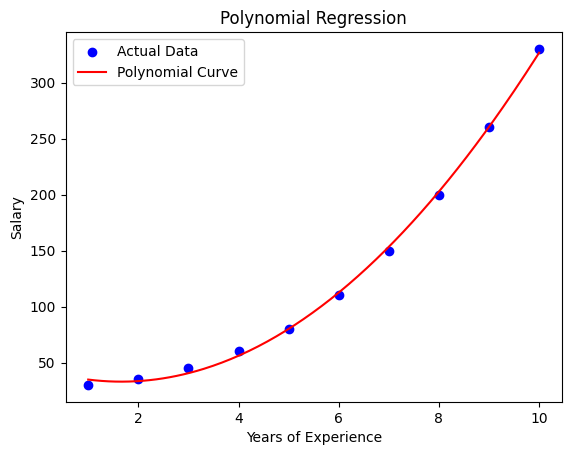

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Create Dataset
data = {
    'Experience': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Salary': [30, 35, 45, 60, 80, 110, 150, 200, 260, 330]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Step 2: Separate Input and Output
X = df[['Experience']]
Y = df['Salary']

# Step 3: Convert into Polynomial Features
poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

# Step 4: Create Linear Regression Model
model = LinearRegression()

# Step 5: Train Model
model.fit(X_poly, Y)

# Step 6: Predict Values
Y_pred = model.predict(X_poly)

print("\nPredicted Values:")
print(Y_pred)

# Step 7: Evaluate Model
mse = mean_squared_error(Y, Y_pred)
r2 = r2_score(Y, Y_pred)

print("\nMean Squared Error:", mse)
print("R2 Score:", r2)

# Step 8: Predict New Value
new_experience = pd.DataFrame({'Experience': [6]})

new_poly = poly.transform(new_experience)

prediction = model.predict(new_poly)

print("\nPredicted Salary for 6 Years:", prediction[0])

# Step 9: Visualize Polynomial Curve
X_curve = pd.DataFrame({
    'Experience': np.linspace(1, 10, 200)
})

X_curve_poly = poly.transform(X_curve)
Y_curve = model.predict(X_curve_poly)

plt.scatter(X, Y, color='blue', label='Actual Data')
plt.plot(X_curve, Y_curve, color='red', label='Polynomial Curve')

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Polynomial Regression")
plt.legend()
plt.show()
